In [9]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

import sys
import os

#from gauss_slicer import * 

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from slicing_class import adcFitter2

In [10]:
#import data
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov9th/counterrotation.fits')
step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_sat.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/zband/z_sparkles_counter_sat.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov5th/counterrotation.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov11th_onsky/onsky_counterrotation.fits')

In [11]:
for img in step: #the dark subtraction isn't working so i had to median subtract the image... should I do this onsky?
       img -= np.median(img)

In [12]:
len(step)

51

In [13]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle,snr_threshold=2.6,speckle_window=70) 

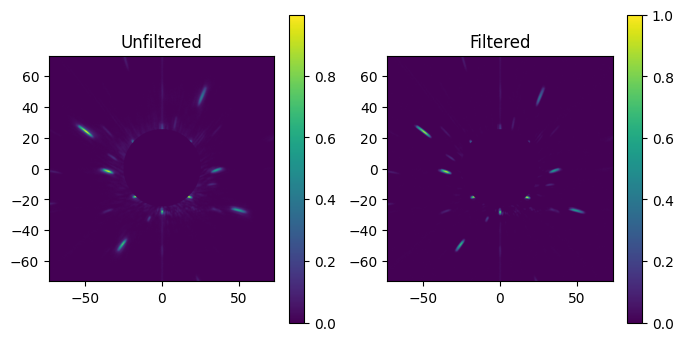

In [14]:
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
im = step[1]
imshow_field(ADC.crop_image(im,mask_diam=50,extent=512))
plt.colorbar()
plt.title('Unfiltered')
plt.subplot(1,2,2)
im_hp = ADC.hpf(im,12)
imshow_field(ADC.crop_image(im_hp,mask_diam=50,extent=512))
plt.title('Filtered')
plt.colorbar()

least-squares solution: (0.259866552401124,-5.527967493111436)
Estimated dispersion direction -92.69145999424006°
Estimated dispersion magnitude 5.534072210402895
est dispersion 5.534072210402895 pixels
est disp axis -87.30854000575994°


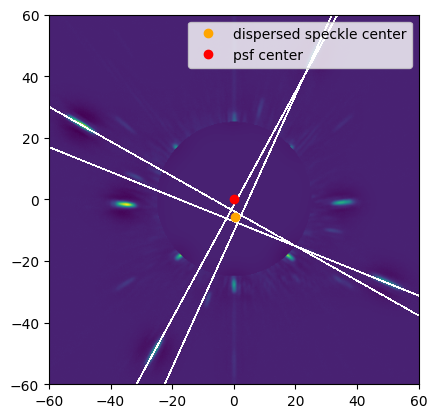

In [15]:
#one single iteration with a gain of one
img_no = 20
im = step[img_no]

#set up dispersed PSF
disps = np.linspace(-5,5,len(step))
dir = 90
# disps_x = np.cos(np.radians(dir)) * disps
# disps_y = np.sin(np.radians(dir)) * disps
# print(f'injected dispersion dx: {disps_x} dy: {disps_y}')

psf = ADC.hpf(ADC.crop_image(im,mask_diam=50,extent=512),12)

#now try and measure it
plt.figure()
est_x, est_y = ADC.speckles_dxdy(psf,plotted=True,printed=True)

#calculate how much to move ADCs
#get the correct quadrant
if est_x >0 and est_y>0:
    sign = -1
elif est_x <0 and est_y>0:
    sign = 1
elif est_x <0 and est_y<0:
    sign = 1
else: sign = -1

sq = np.sqrt(est_x**2+est_y**2)
ang = np.degrees(np.arctan2(est_y,est_x))
print(f'est dispersion {sq} pixels')
print(f'est disp axis {ang}°')
#can't do any control yet because we don't know the response

In [21]:
#go through the whole cube
diffs13_list = [] #list of speckle pair differences for each step
diffs24_list = [] 
speckle_list = [] #speckle angle list at each step
dx_list = [] #dxdy lists for comparison to original method
dy_list = []

for i, field in enumerate(step):
    img = ADC.hpf(field,12)
    img = ADC.crop_image(img,mask_diam=50,extent=512)

    est_x, est_y = ADC.speckles_dxdy(img,plotted=False,printed=False)
    dx_list.append(est_x)
    dy_list.append(est_y)

    if est_x >0 and est_y>0:
        sign = -1
    elif est_x <0 and est_y>0:
        sign = 1
    elif est_x <0 and est_y<0:
        sign = 1
    else: sign = -1

    sq = np.sqrt(est_x**2+est_y**2)
    ang = np.degrees(np.arctan2(est_y,est_x))

    a = ADC.all_speckle_angles(img,speckle_filter=True)
    speckle_list.append(a)
    diffs13_list.append(a[0] - a[2])
    diffs24_list.append(a[1] - a[3])

diffs13_list = np.array(diffs13_list)
diffs24_list = np.array(diffs24_list)
dx_list = np.array(dx_list)
dy_list = np.array(dy_list)

Slope of Speckles 1&3 Response: 1.2935854442043768
Offset of Speckles 1&3 Response: -1.0420805606497276
Slope of Speckles 2&4 Response: -3.6637279881403875
Offset of Speckles 2&4 Response: 2.47205946092609


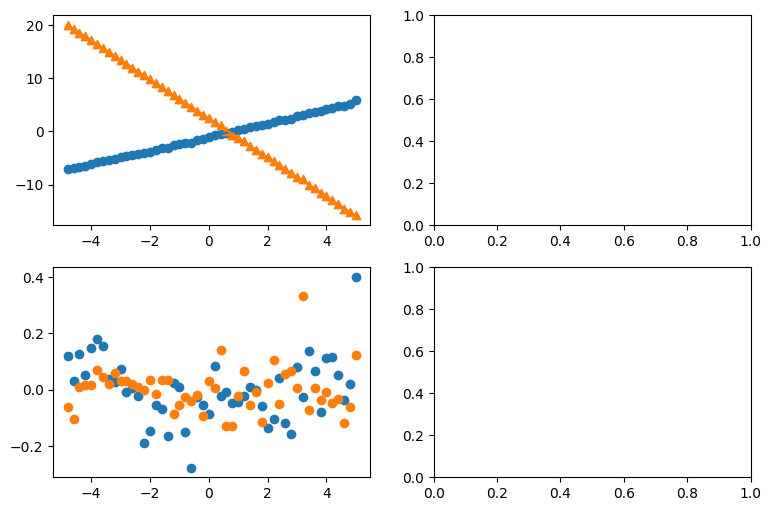

In [ ]:
angle_offsets = np.linspace(-5,5,len(step)) 

b1 = np.zeros(2)
m1 = np.zeros(2)

#only consider finite angles (clean up nan values)
idxs13 = np.isfinite(diffs13_list)
idxs13[0] = False
idxs24 = np.isfinite(diffs24_list)
idxs24[0] = False

avgs = [diffs13_list[idxs13], diffs24_list[idxs24]]
offsets = [angle_offsets[idxs13],angle_offsets[idxs24]]


fig, ax = plt.subplots(2,2,figsize=(9,6))
labels = ['Speckles 1&3','Speckles 2&4']
markers = ['o','^','s','+']

for j in range(2):
    m1[j] , b1[j] = np.polyfit(offsets[j],avgs[j],deg=1)
    ax[0,0].scatter(offsets[j], avgs[j], label=labels[j],marker=markers[j])
    linepoints = b1[j] + m1[j] * offsets[j]
    ax[0,0].plot(offsets[j], linepoints)
    print(f'Slope of {labels[j]} Response: {m1[j]}')
    print(f'Offset of {labels[j]} Response: {b1[j]}')

    resids = avgs[j] - linepoints
    sigma = np.std(resids)
    ax[1,0].scatter(offsets[j],resids,label=f'{labels[j]} std={sigma:.3f}')

b1 = np.zeros(2)
m1 = np.zeros(2)

#only consider finite angles (clean up nan values)
idxs13 = np.isfinite(dx_list)
idxs13[0] = False
idxs24 = np.isfinite(dy_list)
idxs24[0] = False

avgs = [dx_list[idxs13], dy_list[idxs24]]
offsets = [angle_offsets[idxs13],angle_offsets[idxs24]]

labels = ['dx','dy']
markers = ['o','^','s','+']

for j in range(2):
    m1[j] , b1[j] = np.polyfit(offsets[j],avgs[j],deg=1)
    ax[0,1].scatter(offsets[j], avgs[j], label=labels[j],marker=markers[j])
    linepoints = b1[j] + m1[j] * offsets[j]
    ax[0,1].plot(offsets[j], linepoints)
    print(f'Slope of {labels[j]} Response: {m1[j]}')
    print(f'Offset of {labels[j]} Response: {b1[j]}')

    resids = avgs[j] - linepoints
    sigma = np.std(resids)
    ax[1,1].scatter(offsets[j],resids,label=f'{labels[j]} std={sigma:.3f}')

#plt.scatter(0,0,color='Red')
ax[0,0].set_title('ADC Response - Old Method')
ax[0,1].set_title('ADC Response - New Method')
ax[1,0].set_title('Residuals')
ax[1,1].set_title('Residuals')


ax[0,0].set_xlabel('StageADC Offset from (60,-60)')
ax[0,1].set_xlabel('StageADC Offset from (60,-60)')
ax[0,0].set_ylabel('Speckle pair offsets(°)')
ax[0,1].set_ylabel('Dispersion (pixels)')
ax[0,0].legend()
ax[0,1].legend()
ax[1,0].legend()
ax[1,1].legend()


fig.tight_layout()

In [39]:
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (12, 5),
         'axes.labelsize': 'large',
         'axes.titlesize':'large',
         'xtick.labelsize':'medium',
         'ytick.labelsize':'medium',
         'font.family':'serif'}
pylab.rcParams.update(params)

Slope of Spots 1&3 Response: 1.2935854442043768
Offset of Spots 1&3 Response: -1.0420805606497276
Slope of Spots 2&4 Response: -3.6637279881403875
Offset of Spots 2&4 Response: 2.47205946092609


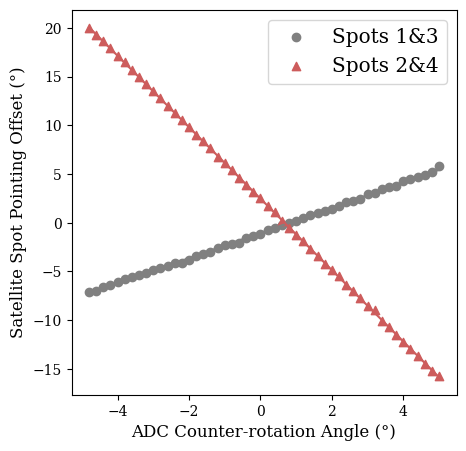

In [40]:
#making a figure showing the adc response for my spie 26 slides
fig, ax = plt.subplots(1,1,figsize=(7,5))
labels = ['Spots 1&3','Spots 2&4']
markers = ['o','^','s','+']
colors= ['grey','indianred']

for j in range(2):
    m1[j] , b1[j] = np.polyfit(offsets[j],avgs[j],deg=1)
    ax.scatter(offsets[j], avgs[j], label=labels[j],marker=markers[j],c=colors[j])
    linepoints = b1[j] + m1[j] * offsets[j]
    ax.plot(offsets[j], linepoints,color=colors[j])
    print(f'Slope of {labels[j]} Response: {m1[j]}')
    print(f'Offset of {labels[j]} Response: {b1[j]}')

    # resids = avgs[j] - linepoints
    # sigma = np.std(resids)
    # ax.scatter(offsets[j],resids,label=f'{labels[j]} std={sigma:.3f}')

ax.set_ylabel('Satellite Spot Pointing Offset (°)')
ax.set_xlabel('ADC Counter-rotation Angle (°)')
ax.legend()
ax.set_box_aspect(1)

In [41]:
fig.savefig('/Users/Katie/Documents/MagAO-X/figures/ADC/SPIE_26/adc_response.png',dpi=300)